# Food prices in Côte d'Ivoire: analysis

Data: WFP food prices (HDX), cleaned with `src/cleaning.py`. All prices are compared in **XOF per kg** (`price_xof_per_kg`).

Questions answered:
1. Which staples had the largest price increase over the period?
2. Do prices differ significantly between Abidjan and the other regions?
3. Is there seasonality?
4. Can price shocks be detected automatically with a rolling z-score?

**Methodological choices that apply to the whole notebook**
- Rows with `is_outlier == True` are **kept**: Q4 is precisely about extreme movements, and Q1–Q3 use **medians**, which are not affected much by a few extreme values.
- Markets enter and leave the dataset over time (e.g. Bouaké stops in 2014, Korhogo starts in 2016). To avoid confusing a change of markets with a change of prices, comparisons are made **within the same market** (Q1, Q3, Q4) or **for the same month** (Q2).

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.cleaning import load_raw, clean

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

df = clean(load_raw())
print(df.shape)
print(df["date"].min().date(), "->", df["date"].max().date())
df.head()

(10992, 18)
2005-01-15 -> 2026-09-15


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,price,usdprice,kg_per_unit,price_xof_per_kg,price_usd_per_kg,is_outlier
0,2026-06-15,Zanzan,Gontougo,Bondoukou,7667,8.04,-2.80,pulses and nuts,Beans (niebe),120,KG,actual,750.00,1.32,1.00,750.00,1.32,False
1,2026-07-15,Zanzan,Gontougo,Bondoukou,7667,8.04,-2.80,pulses and nuts,Beans (niebe),120,KG,actual,762.50,1.33,1.00,762.50,1.33,False
2,2026-08-15,Zanzan,Gontougo,Bondoukou,7667,8.04,-2.80,pulses and nuts,Beans (niebe),120,KG,actual,812.50,1.43,1.00,812.50,1.43,False
3,2026-09-15,Zanzan,Gontougo,Bondoukou,7667,8.04,-2.80,pulses and nuts,Beans (niebe),120,KG,actual,812.50,1.43,1.00,812.50,1.43,False
4,2026-06-15,Zanzan,Bounkani,Bouna,7684,9.27,-3.00,pulses and nuts,Beans (niebe),120,KG,actual,750.00,1.32,1.00,750.00,1.32,False


In [2]:
# Staples studied in Q1 and Q3
STAPLES = [
    "Maize", "Cornstarch",
    "Rice (local)", "Rice (denikassia, imported)", "Rice (imported)",
    "Cassava (fresh)", "Cassava meal (attieke)",
    "Yam (florido)", "Yam", "Plantains",
    "Beans (niebe)", "Peanut", "Oil (palm)",
]


def monthly_series(group: pd.DataFrame) -> pd.Series:
    """Price series of one commodity x market on a complete monthly calendar.
    Missing months become NaN (instead of being silently skipped)."""
    s = group.set_index("date")["price_xof_per_kg"].sort_index()
    s.index = s.index.to_period("M")
    return s.reindex(pd.period_range(s.index.min(), s.index.max(), freq="M"))

## Q1. Which staples had the largest price increase?

**Method**
- For each **commodity × market** series covering at least 5 years, compare the median price of its **first 12 months** with that of its **last 12 months**. Using a full year at each end removes seasonality and one-off shocks.
- Series start and end at different dates, so the change is also expressed as an **annual growth rate** (CAGR): `(end / start) ** (1 / years) - 1`.
- For each commodity, take the **median across markets**.

In [3]:
rows = []
for (commodity, market), g in df[df["commodity"].isin(STAPLES)].groupby(["commodity", "market"]):
    start, end = g["date"].min(), g["date"].max()
    years = (end - start).days / 365.25
    if years < 5:
        continue
    p_start = g.loc[g["date"] < start + pd.DateOffset(months=12), "price_xof_per_kg"].median()
    p_end = g.loc[g["date"] > end - pd.DateOffset(months=12), "price_xof_per_kg"].median()
    span = years - 1  # distance between the centres of the two 12-month windows
    rows.append({
        "commodity": commodity, "market": market,
        "start": start.year, "end": end.year,
        "price_start": p_start, "price_end": p_end,
        "total_change_pct": (p_end / p_start - 1) * 100,
        "cagr_pct": ((p_end / p_start) ** (1 / span) - 1) * 100,
    })

series_growth = pd.DataFrame(rows)

growth = (
    series_growth.groupby("commodity")
    .agg(n_markets=("market", "size"),
         first_year=("start", "min"), last_year=("end", "max"),
         median_cagr_pct=("cagr_pct", "median"),
         median_total_change_pct=("total_change_pct", "median"))
    .sort_values("median_cagr_pct", ascending=False)
)
growth

,n_markets,first_year,last_year,median_cagr_pct,median_total_change_pct
commodity,,,,,
Yam (florido),8,2006,2026,9.21,83.92
Beans (niebe),4,2019,2026,5.58,41.96
Maize,10,2005,2026,5.08,54.58
Cassava (fresh),10,2006,2026,4.11,41.11
"Rice (denikassia, imported)",10,2005,2026,4.08,37.65
Cornstarch,7,2011,2026,3.81,28.87
Rice (local),10,2006,2026,3.57,30.60
Oil (palm),3,2011,2026,2.96,51.94
Peanut,7,2011,2026,2.70,31.25


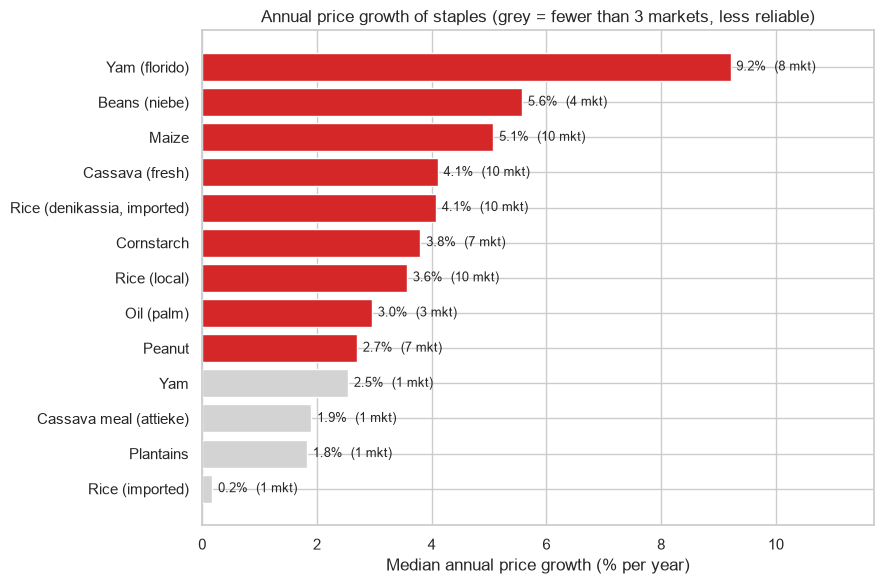

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_data = growth.sort_values("median_cagr_pct")
colors = ["tab:red" if n >= 3 else "lightgray" for n in plot_data["n_markets"]]
ax.barh(plot_data.index, plot_data["median_cagr_pct"], color=colors)
for i, (v, n) in enumerate(zip(plot_data["median_cagr_pct"], plot_data["n_markets"])):
    ax.text(v + 0.1, i, f"{v:.1f}%  ({n} mkt)", va="center", fontsize=9)
ax.set_xlabel("Median annual price growth (% per year)")
ax.set_title("Annual price growth of staples (grey = fewer than 3 markets, less reliable)")
ax.set_xlim(0, plot_data["median_cagr_pct"].max() + 2.5)
plt.tight_layout()
plt.show()

**Conclusion Q1**
- Among staples observed in at least 3 markets, **yam (florido)** rose fastest: about **+9% per year** (median total change ≈ +84%). It is followed by **cowpeas (niébé)** (+5.6%/yr), **maize** (+5.1%/yr, ≈ +55% in total) and **fresh cassava** (+4.1%/yr).
- **Rice** rose more slowly: imported denikassia rice +4.1%/yr and local rice +3.6%/yr.
- These rates are above the WAEMU inflation ceiling (3% per year), so these staples became more expensive **in real terms**, not only in nominal terms.
- Products observed in a single market (yam, attiéké, plantains, imported rice) are shown in grey: their ranking rests on one series and should not be over-interpreted.

## Q2. Do prices differ significantly between Abidjan and the other regions?

**Important limitation:** Abidjan is represented by **a single market, Adjamé**, observed from 2011 to 2021. The comparison is therefore "Adjamé vs. the rest of the country".

**Method**
- For each commodity and each month, compute the gap: `log(price in Adjamé) − log(median price in the other markets that month)`. Comparing the **same product in the same month** neutralises inflation and seasonality.
- A gap of +0.10 means Adjamé is about 10% more expensive.
- Test whether the median gap differs from 0 with the **Wilcoxon signed-rank test** (non-parametric, suited to non-normal price data).
- 11 products are tested, so the significance threshold is corrected with **Bonferroni**: 0.05 / 11 ≈ 0.0045. Only products with at least 12 paired months are tested.

In [5]:
abidjan = (df[df["admin1"] == "Abidjan"]
           .groupby(["commodity", "date"])["price_xof_per_kg"].median()
           .rename("abidjan"))
others = (df[df["admin1"] != "Abidjan"]
          .groupby(["commodity", "date"])["price_xof_per_kg"].median()
          .rename("others"))
paired = pd.concat([abidjan, others], axis=1, join="inner").reset_index()
paired["log_gap"] = np.log(paired["abidjan"] / paired["others"])

results = []
for commodity, g in paired.groupby("commodity"):
    if len(g) < 12:
        continue
    results.append({
        "commodity": commodity,
        "n_months": len(g),
        "median_gap_pct": (np.exp(g["log_gap"].median()) - 1) * 100,
        "p_value": stats.wilcoxon(g["log_gap"]).pvalue,
    })

abj = pd.DataFrame(results).sort_values("median_gap_pct", ascending=False)
alpha = 0.05 / len(abj)
abj["significant"] = abj["p_value"] < alpha
print(f"Bonferroni threshold: {alpha:.4f}")
abj

Bonferroni threshold: 0.0045


,commodity,n_months,median_gap_pct,p_value,significant
0,Cassava (fresh),110,77.02,0.00,True
7,Peanut,14,45.38,0.00,True
6,Oil (palm),14,31.86,0.00,True
10,Rice (local),117,22.00,0.00,True
4,Maize,57,18.10,0.00,True
1,Cornstarch,14,16.07,0.02,False
2,Fish (appolo),14,10.66,0.00,True
5,Meat (beef),108,8.90,0.00,True
9,"Rice (denikassia, imported)",57,3.45,0.25,False
3,Fish (dry),14,0.00,0.22,False


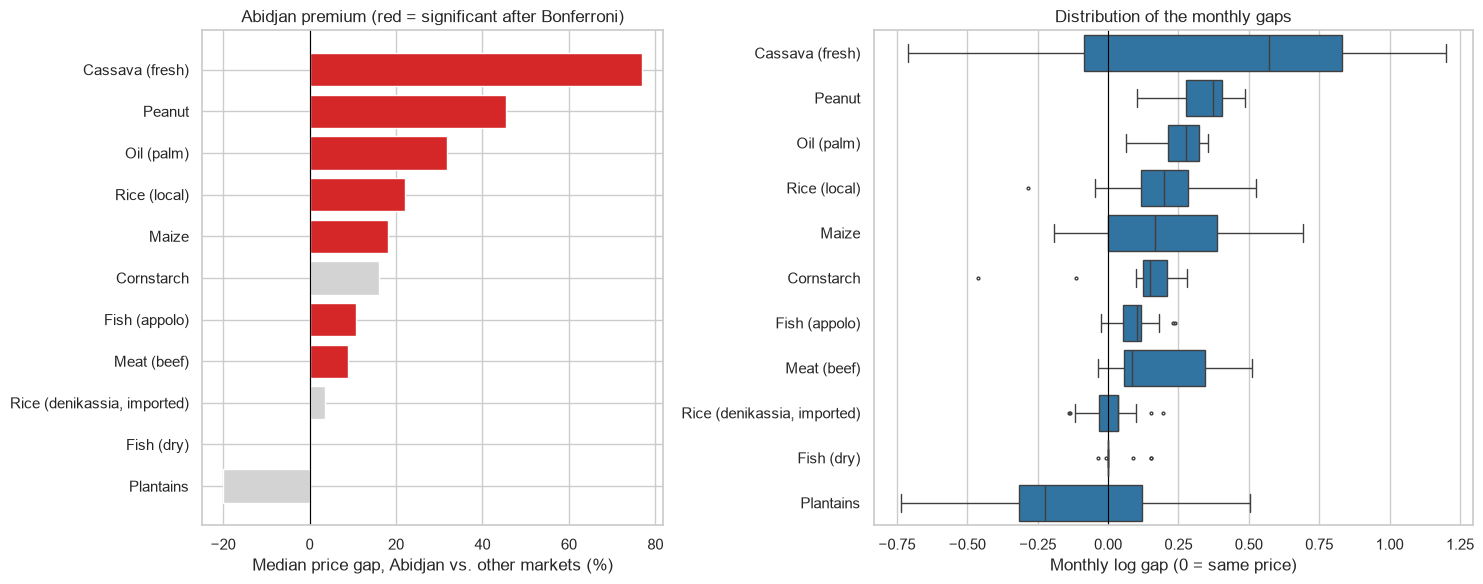

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.3]})

plot_data = abj.sort_values("median_gap_pct")
colors = ["tab:red" if s else "lightgray" for s in plot_data["significant"]]
axes[0].barh(plot_data["commodity"], plot_data["median_gap_pct"], color=colors)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_xlabel("Median price gap, Abidjan vs. other markets (%)")
axes[0].set_title("Abidjan premium (red = significant after Bonferroni)")

order = plot_data["commodity"].tolist()
sns.boxplot(data=paired[paired["commodity"].isin(order)], y="commodity", x="log_gap",
            order=order[::-1], ax=axes[1], color="tab:blue", fliersize=2)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("Monthly log gap (0 = same price)")
axes[1].set_ylabel("")
axes[1].set_title("Distribution of the monthly gaps")
plt.tight_layout()
plt.show()

**Conclusion Q2**
- **Yes, for most products Abidjan is significantly more expensive.** The premium is largest for **fresh cassava (≈ +77%)**, then peanuts (≈ +45%), palm oil (≈ +32%), local rice (≈ +22%) and maize (≈ +18%), all significant after Bonferroni correction.
- **Beef (≈ +9%)** and **appolo fish (≈ +11%)** are also significantly more expensive, but with a smaller premium.
- The largest premiums concern **locally produced** goods: the Abidjan premium is consistent with transport costs from producing areas and higher urban costs. Fresh cassava is bulky and perishable, which explains the very large gap.
- **Imported denikassia rice** (≈ +3%), cornstarch, dry fish and plantains show no significant gap. Imported rice arrives through the port of Abidjan and is then distributed nationwide, so its price is fairly uniform.
- Some products have few paired months (14 for peanuts, oil, cornstarch), so their estimates are less precise.

## Q3. Is there seasonality?

**Method**
- Seasonality is hidden by the long-term trend (inflation). For each commodity × market series with at least 36 months of data, the trend is removed by dividing each price by its **centred 12-month moving average**.
- The ratio is averaged by calendar month. A value of +5% in July means "prices are 5% above their trend in July".
- A **Kruskal-Wallis test** checks whether the ratios really differ between months (p < 0.05 means seasonality is significant).

In [7]:
seasonal_parts = []
for (commodity, market), g in df[df["commodity"].isin(STAPLES)].groupby(["commodity", "market"]):
    s = monthly_series(g)
    if s.notna().sum() < 36:
        continue
    trend = s.interpolate(limit=2).rolling(12, center=True, min_periods=12).mean()
    ratio = (s / trend).dropna()
    seasonal_parts.append(pd.DataFrame({
        "commodity": commodity, "market": market,
        "month": ratio.index.month, "ratio": ratio.values,
    }))
seasonal = pd.concat(seasonal_parts)

profile = (seasonal.groupby(["commodity", "month"])["ratio"].mean().unstack() - 1) * 100

tests = []
for commodity, g in seasonal.groupby("commodity"):
    tests.append({
        "commodity": commodity,
        "n_markets": g["market"].nunique(),
        "amplitude_pct": profile.loc[commodity].max() - profile.loc[commodity].min(),
        "peak_month": profile.loc[commodity].idxmax(),
        "low_month": profile.loc[commodity].idxmin(),
        "kruskal_p": stats.kruskal(*[x["ratio"] for _, x in g.groupby("month")]).pvalue,
    })
season_tests = pd.DataFrame(tests).set_index("commodity").sort_values("amplitude_pct", ascending=False)
season_tests["significant"] = season_tests["kruskal_p"] < 0.05
season_tests

,n_markets,amplitude_pct,peak_month,low_month,kruskal_p,significant
commodity,,,,,,
Plantains,1,75.59,6,11,0.00,True
Yam (florido),5,37.10,8,5,0.50,False
Yam,1,36.33,6,11,0.01,True
Cassava meal (attieke),1,15.37,6,10,0.02,True
Oil (palm),5,14.13,1,5,0.00,True
Maize,13,13.60,7,12,0.00,True
Cassava (fresh),11,12.95,3,9,0.00,True
Peanut,9,11.76,8,12,0.00,True
Cornstarch,9,8.99,5,12,0.02,True


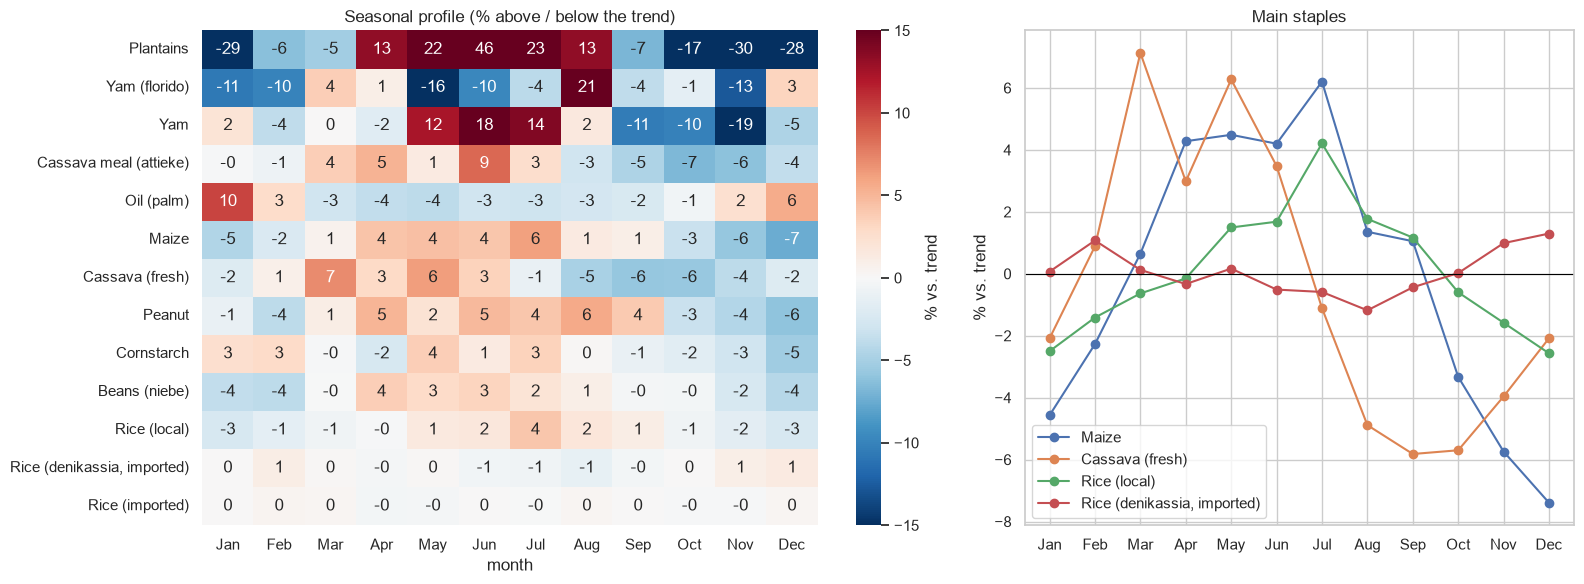

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
heat = profile.loc[season_tests.index]
sns.heatmap(heat, cmap="RdBu_r", center=0, vmin=-15, vmax=15, annot=True, fmt=".0f",
            xticklabels=month_labels, cbar_kws={"label": "% vs. trend"}, ax=axes[0])
axes[0].set_title("Seasonal profile (% above / below the trend)")
axes[0].set_ylabel("")

for commodity in ["Maize", "Cassava (fresh)", "Rice (local)", "Rice (denikassia, imported)"]:
    axes[1].plot(range(1, 13), profile.loc[commodity], marker="o", label=commodity)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xticks(range(1, 13), month_labels)
axes[1].set_ylabel("% vs. trend")
axes[1].set_title("Main staples")
axes[1].legend()
plt.tight_layout()
plt.show()

**Conclusion Q3**
- **Locally produced staples are clearly seasonal** (Kruskal-Wallis p < 0.05):
  - **Maize**: prices rise from April to July (≈ +4 to +6% above trend) and are lowest in November–December (≈ −6 to −7%), right after the harvest. Amplitude ≈ 14%.
  - **Fresh cassava**: highest in March–June, lowest in August–October. Amplitude ≈ 13%.
  - **Local rice**: same pattern but weaker (peak in July, ≈ 7% amplitude).
  - **Peanuts** (peak in August) and **cowpeas** follow a similar pattern. **Palm oil** is the exception: it is most expensive in December–January and cheapest in spring, which matches the palm oil production cycle.
  - This is the classic **lean season (*soudure*)** pattern: prices rise as the previous harvest's stocks run out, then fall when the new harvest arrives.
- **Imported rice shows no significant seasonality** (amplitude 1–2.5%, p > 0.3): its price follows world markets and import flows, not the local farming calendar.
- Plantains and yam show very large amplitudes (36–76%) but rely on 1–3 markets. Yam (florido) is not significant (p ≈ 0.5), so its profile is mostly noise.

## Q4. Automatic detection of price shocks (rolling z-score)

**Method**
1. For each commodity × market series on a complete monthly calendar, compute the **monthly change** `Δ = log(price_t) − log(price_t−1)`. A shock is a sudden **jump**, not a high level.
2. Compare each change with the **12 previous months**:
   `z_t = (Δ_t − mean(Δ_{t−12..t−1})) / std(Δ_{t−12..t−1})`
   - `.shift(1)` makes sure month *t* is compared only with the past, so a shock does not hide itself by inflating its own reference values.
   - `min_periods=6`: no z-score is computed with fewer than 6 months of history.
3. A month is a **shock** if **|z| > 3 and |Δ| ≥ 10%**.

In [9]:
def rolling_z(s: pd.Series, window: int = 12, min_periods: int = 6) -> pd.DataFrame:
    change = np.log(s).diff()
    past = change.shift(1).rolling(window, min_periods=min_periods)
    z = (change - past.mean()) / past.std()
    return pd.DataFrame({"price": s, "change": change, "z": z})


parts = []
for (commodity, market), g in df.groupby(["commodity", "market"]):
    r = rolling_z(monthly_series(g))
    r["commodity"], r["market"] = commodity, market
    parts.append(r)

zdf = pd.concat(parts).rename_axis("month").reset_index()
zdf = zdf[np.isfinite(zdf["z"])]
print(f"{len(zdf)} monthly changes with a valid z-score")

8260 monthly changes with a valid z-score


### Choosing the threshold

The table compares, for several thresholds, the share of months flagged with what a normal distribution would give.

In [10]:
rows = []
for min_change in [0, 0.10, 0.15]:
    for k in [2, 2.5, 3, 3.5]:
        flagged = (zdf["z"].abs() > k) & (zdf["change"].abs() >= min_change)
        rows.append({"min_change": f"{min_change:.0%}", "k": k,
                     "n_shocks": flagged.sum(),
                     "pct_flagged": flagged.mean() * 100,
                     "pct_expected_if_normal": 2 * stats.norm.sf(k) * 100})
pd.DataFrame(rows).pivot(index="k", columns="min_change", values="pct_flagged").assign(
    normal=[2 * stats.norm.sf(k) * 100 for k in [2, 2.5, 3, 3.5]])

min_change,0%,10%,15%,normal
k,,,,
2.00,10.45,7.64,5.76,4.55
2.50,7.06,5.45,4.38,1.24
3.00,5.05,4.00,3.23,0.27
3.50,3.64,2.92,2.36,0.05


In [11]:
# Why a minimum change is needed: many prices stay flat for months,
# so the rolling std is close to 0 and tiny changes get huge z-scores.
zdf[(zdf["z"].abs() > 3) & (zdf["change"].abs() < 0.10)].sort_values("z", key=abs, ascending=False).head(5)

,month,price,change,z,commodity,market
10615,2015-06,362.00,0.07,72.39,"Rice (denikassia, imported)",Guiglo
9872,2013-12,350.00,0.06,9.72,"Rice (denikassia, imported)",Abengourou
2219,2019-10,825.00,0.10,9.45,Cocoa,Man
11405,2013-12,400.00,0.10,9.43,Rice (local),Abengourou
4910,2018-02,2700.00,-0.09,-8.04,Fish (dry),Korhogo


**Threshold chosen: |z| > 3 and |Δ| ≥ 10%**
- **k = 3** is the classic "3-sigma" rule: under a normal distribution only 0.27% of months would exceed it. Here 5% of months do, because price changes have **heavy tails** (long calm periods, then sudden jumps). With k = 2, more than 10% of months would be flagged: too many to be called "shocks".
- **|Δ| ≥ 10%**: when a price stays unchanged for months, the rolling standard deviation is almost 0, and a small change gets an enormous z-score (the table above shows such cases). The 10% floor keeps only changes that matter economically for households.
- Together, the two conditions flag about **4% of months**, i.e. roughly one shock every two years per series.

In [12]:
zdf["shock"] = (zdf["z"].abs() > 3) & (zdf["change"].abs() >= 0.10)
shocks = zdf[zdf["shock"]].copy()
shocks["direction"] = np.where(shocks["change"] > 0, "increase", "decrease")
print(f"{len(shocks)} shocks detected, {(shocks['direction'] == 'increase').mean():.0%} are increases")

display(shocks.groupby("commodity").size().sort_values(ascending=False).head(8).rename("n_shocks"))
display(shocks.groupby(shocks["month"].astype(str)).size().sort_values(ascending=False).head(8).rename("n_series_in_shock"))

330 shocks detected, 53% are increases


commodity
Maize                          46
Cassava (fresh)                39
Peanut                         33
Cornstarch                     32
Rice (local)                   31
Fish (dry)                     28
Rice (denikassia, imported)    26
Meat (beef)                    21
Name: n_shocks, dtype: int64

month
2012-11    10
2021-01     9
2022-02     8
2014-08     7
2017-03     6
2021-02     6
2021-05     5
2012-10     5
Name: n_series_in_shock, dtype: int64

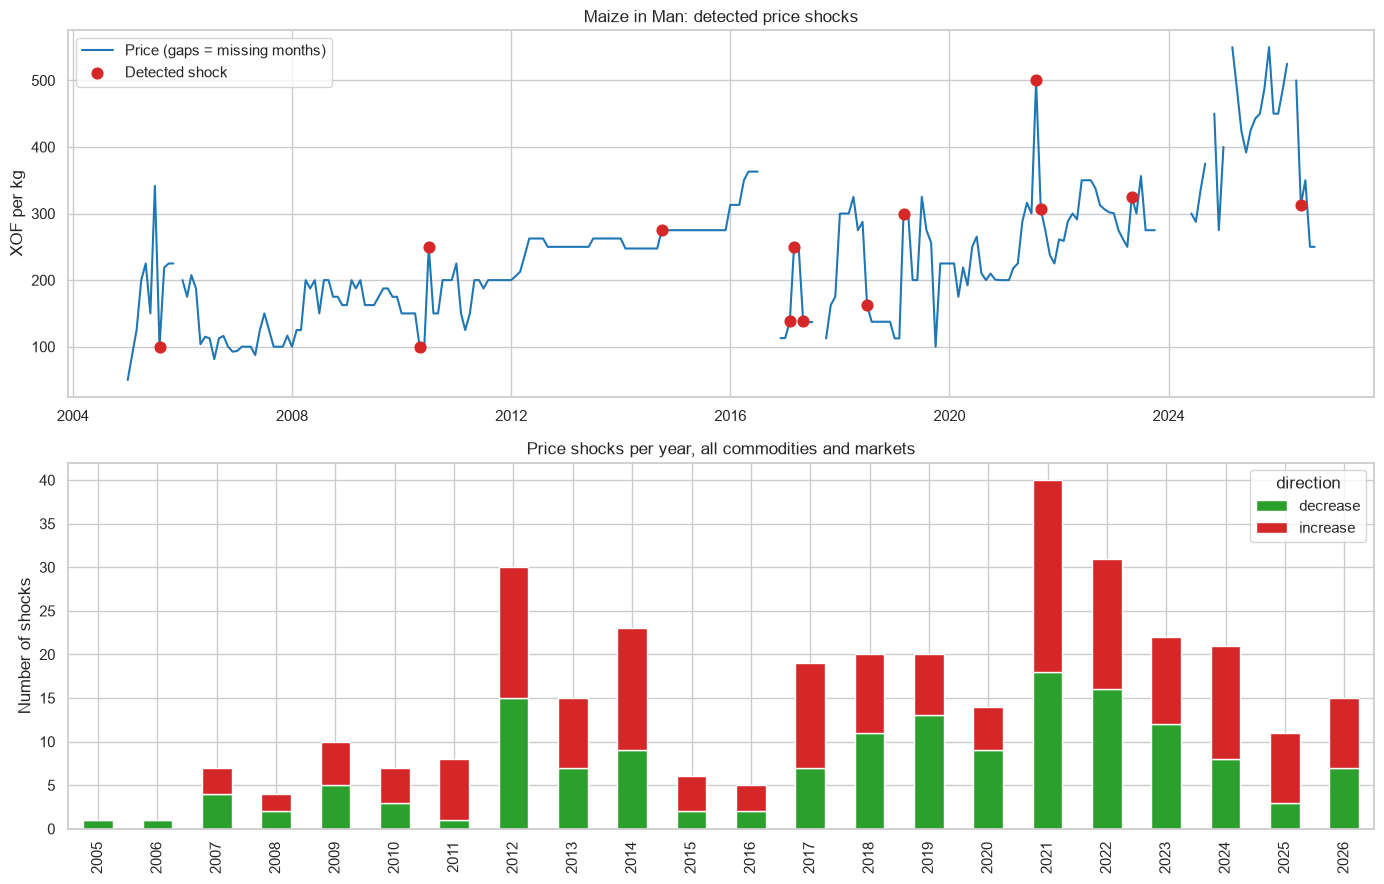

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Example: maize in Man, the longest series in the dataset
full = monthly_series(df[(df["commodity"] == "Maize") & (df["market"] == "Man")])
axes[0].plot(full.index.to_timestamp(), full.values, color="tab:blue", lw=1.5, label="Price (gaps = missing months)")
pts = zdf[(zdf["commodity"] == "Maize") & (zdf["market"] == "Man") & zdf["shock"]]
axes[0].scatter(pts["month"].dt.to_timestamp(), pts["price"], color="tab:red", s=60, zorder=3, label="Detected shock")
axes[0].set_ylabel("XOF per kg")
axes[0].set_title("Maize in Man: detected price shocks")
axes[0].legend()

# Shocks per year, all series
per_year = shocks.groupby([shocks["month"].dt.year, "direction"]).size().unstack(fill_value=0)
per_year.plot(kind="bar", stacked=True, ax=axes[1], color={"increase": "tab:red", "decrease": "tab:green"})
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of shocks")
axes[1].set_title("Price shocks per year, all commodities and markets")
plt.tight_layout()
plt.show()

**Conclusion Q4**
- Yes: a rolling z-score on monthly log changes detects shocks automatically. With **|z| > 3 and |Δ| ≥ 10%**, about **330 shocks** are found, split roughly evenly between increases and decreases (prices often fall back after a spike).
- The products with the most shocks are **maize, fresh cassava, peanuts and cornstarch**: local, seasonal goods that are sensitive to harvests and transport.
- Shocks cluster in time, which suggests national or global causes rather than local noise:
  - **2012–2014**, after the 2010–2011 post-electoral crisis;
  - **2021–2022**, the year with the most shocks, at the time of the global food price surge (post-COVID recovery, then the war in Ukraine from February 2022).
- These links to events are **hypotheses** to check against external sources, not causal proof.
- **Caveat:** the number of shocks per year also depends on how many markets are monitored that year (many markets start in 2019), so the yearly counts should be compared with care.

## Limitations
- **Uneven coverage:** markets and products enter and leave the dataset; several series (cassava, maize flour, vegetable oil, fuel) only start in 2026.
- **Abidjan = one market** (Adjamé, 2011–2021): Q2 compares Adjamé with the rest of the country, not the whole city.
- **Unit conversion:** prices per litre (palm oil) are converted to kg with an approximate density (0.91 kg/L).
- **`priceflag`:** about 38% of prices are `aggregate` (computed by WFP) rather than directly observed.
- **Nominal prices:** prices are not deflated by the consumer price index, so part of the increases in Q1 is general inflation.